<a href="https://colab.research.google.com/github/ZahwaAulia/Projek-Statistika-dan-Probabilitas_Kelompok_1/blob/main/Probstik_Kel_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Upload file Excel
uploaded = files.upload()

# Membaca file Excel yang diupload
nama_file = next(iter(uploaded))
df = pd.read_excel(nama_file)


Saving 3TIE_01_LaptopPrice (1).xlsx to 3TIE_01_LaptopPrice (1) (1).xlsx


In [ ]:
# Mengubah nama kolom
df = df.rename(columns={
    "Ram": "Ram_GB",
    "Storage": "Storage_GB"
})

print("Data berhasil dibaca.")
print("Ukuran data:", df.shape)
print("\nLima data pertama:")
print(df.head())

Data berhasil dibaca.
Ukuran data: (1303, 14)

Lima data pertama:
   laptop_ID Company      Product   TypeName  Inches  \
0          1   Apple  MacBook Pro  Ultrabook    13.3   
1          2   Apple  Macbook Air  Ultrabook    13.3   
2          3      HP       250 G6   Notebook    15.6   
3          4   Apple  MacBook Pro  Ultrabook    15.4   
4          5   Apple  MacBook Pro  Ultrabook    13.3   

                     ScreenResolution                         Cpu  Ram_GB  \
0  IPS Panel Retina Display 2560x1600        Intel Core i5 2.3GHz       8   
1                            1440x900        Intel Core i5 1.8GHz       8   
2                   Full HD 1920x1080  Intel Core i5 7200U 2.5GHz       8   
3  IPS Panel Retina Display 2880x1800        Intel Core i7 2.7GHz      16   
4  IPS Panel Retina Display 2560x1600        Intel Core i5 3.1GHz       8   

   Storage_GB                           Gpu  OpSys  Weight  Price_euros  \
0         128  Intel Iris Plus Graphics 640  macOS    1.37 

In [ ]:
print("Jumlah baris, kolom :", df.shape)
print("Nilai kosong        :", df.isna().sum().sum())
print("Baris ganda         :", df.duplicated().sum())
print(df[["Price_euros", "Ram_GB", "Storage_GB"]].dtypes)

Jumlah baris, kolom : (1303, 14)
Nilai kosong        : 0
Baris ganda         : 0
Price_euros    float64
Ram_GB           int64
Storage_GB       int64
dtype: object


In [ ]:
# Statistika deskriptif
def ringkas(x):
    q1, q2, q3 = x.quantile([0.25, 0.5, 0.75])
    iqr = q3 - q1
    batas_atas = q3 + 1.5 * iqr
    return pd.Series({
        "n": x.count(), "rata-rata": x.mean(), "median": q2,
        "modus": x.mode()[0], "std": x.std(), "varians": x.var(),
        "CV (%)": x.std() / x.mean() * 100, "min": x.min(),
        "Q1": q1, "Q3": q3, "maks": x.max(), "rentang": x.max() - x.min(),
        "IQR": iqr, "skewness": x.skew(),
        "pencilan": (x > batas_atas).sum()})

tabel = pd.DataFrame({
    "Harga": ringkas(df["Price_euros"]),
    "RAM": ringkas(df["Ram_GB"]),
    "Penyimpanan": ringkas(df["Storage_GB"])}).round(2)
print(tabel)

               Harga      RAM  Penyimpanan
n            1303.00  1303.00      1303.00
rata-rata    1123.69     8.38       620.10
median        977.00     8.00       500.00
modus        1099.00     8.00       256.00
std           699.01     5.08       479.73
varians    488613.64    25.85    230144.18
CV (%)         62.21    60.66        77.36
min           174.00     2.00         8.00
Q1            599.00     4.00       256.00
Q3           1487.88     8.00      1024.00
maks         6099.00    64.00      2560.00
rentang      5925.00    62.00      2552.00
IQR           888.88     4.00       768.00
skewness        1.52     2.69         1.05
pencilan       29.00   221.00        13.00


In [ ]:

# Distribusi frekuensi harga (aturan Sturges)
n = len(df)
k = round(1 + 3.322 * np.log10(n))

lebar = np.ceil(
    (df.Price_euros.max() - df.Price_euros.min()) / k / 100
) * 100

awal = np.floor(df.Price_euros.min() / 100) * 100
batas = np.arange(
    awal,
    df.Price_euros.max() + lebar,
    lebar
)

frek = pd.cut(
    df.Price_euros,
    bins=batas,
    right=False
).value_counts(sort=False)

dist = pd.DataFrame({
    "frekuensi": frek,
    "persen": (frek / n * 100).round(1)
})

dist["persen kumulatif"] = dist["persen"].cumsum().round(1)

print(dist)


                  frekuensi  persen  persen kumulatif
Price_euros                                          
[100.0, 700.0)          421    32.3              32.3
[700.0, 1300.0)         473    36.3              68.6
[1300.0, 1900.0)        244    18.7              87.3
[1900.0, 2500.0)        110     8.4              95.7
[2500.0, 3100.0)         39     3.0              98.7
[3100.0, 3700.0)          9     0.7              99.4
[3700.0, 4300.0)          3     0.2              99.6
[4300.0, 4900.0)          2     0.2              99.8
[4900.0, 5500.0)          1     0.1              99.9
[5500.0, 6100.0)          1     0.1             100.0


In [ ]:

# Frekuensi RAM
print(df["Ram_GB"].value_counts().sort_index())

# Frekuensi kapasitas penyimpanan
kelas = pd.cut(
    df["Storage_GB"],
    bins=[0, 127, 255, 511, 1023, 2047, 10000],
    labels=[
        "<128",
        "128-255",
        "256-511",
        "512-1023",
        "1024-2047",
        ">=2048"
    ]
)

print(kelas.value_counts(sort=False))


Ram_GB
2      22
4     375
6      41
8     619
12     25
16    200
24      3
32     17
64      1
Name: count, dtype: int64
Storage_GB
<128          72
128-255       87
256-511      553
512-1023     125
1024-2047    432
>=2048        34
Name: count, dtype: int64


In [ ]:

# Harga berdasarkan kelompok RAM
df["Kelompok_RAM"] = df["Ram_GB"].apply(
    lambda r: "24+" if r >= 24 else str(r)
)

urut = ["2", "4", "6", "8", "12", "16", "24+"]

per_ram = (
    df.groupby("Kelompok_RAM")["Price_euros"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .reindex(urut)
    .round(2)
)

print(per_ram)


              count     mean   median      std      min     max
Kelompok_RAM                                                   
2                22   254.37   234.00    62.77   174.00   379.0
4               375   574.57   498.00   274.19   196.00  1799.0
6                41   615.21   579.00   125.92   409.00   949.0
8               619  1180.81  1099.00   470.95   329.00  3949.4
12               25  1239.44  1249.00   470.94   609.00  2299.0
16              200  1936.77  1890.50   576.91   859.01  4389.0
24+              21  3267.45  3072.89  1168.98  1269.00  6099.0


In [ ]:

# Korelasi antarvariabel
print(
    df[[
        "Price_euros",
        "Ram_GB",
        "Storage_GB"
    ]].corr().round(3)
)


             Price_euros  Ram_GB  Storage_GB
Price_euros        1.000   0.743       0.158
Ram_GB             0.743   1.000       0.349
Storage_GB         0.158   0.349       1.000


In [ ]:

# Harga berdasarkan jenis penyimpanan
hasil = (
    df.groupby("Memory_Type")
    .agg(
        n=("Price_euros", "count"),
        rata2=("Price_euros", "mean"),
        median=("Price_euros", "median"),
        median_simpan=("Storage_GB", "median")
    )
    .sort_values("n", ascending=False)
    .head(4)
    .round(2)
)

print(hasil)


                 n    rata2  median  median_simpan
Memory_Type                                       
SSD            641  1313.68  1195.0          256.0
HDD            375   655.30   598.0         1024.0
SSD + HDD      200  1613.46  1397.5         1280.0
Flash Storage   74   507.81   329.5           32.0


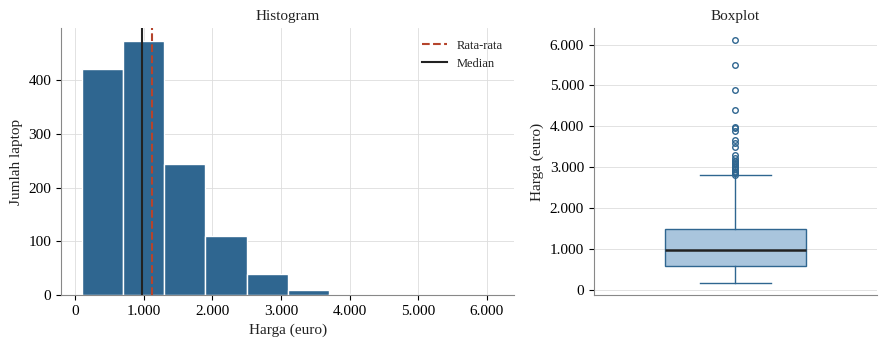

In [ ]:
from matplotlib.ticker import FuncFormatter

# Pengaturan warna
BIRU = "#2F6690"
MUDA = "#A9C5DD"

# Pengaturan tampilan grafik
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",
        "Liberation Serif",
        "DejaVu Serif"
    ],
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#DDDDDD",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.edgecolor": "#888888",
    "text.color": "#222222",
    "axes.labelcolor": "#222222"
})

# Format angka dengan pemisah ribuan titik
titik = FuncFormatter(
    lambda v, p: f"{v:,.0f}".replace(",", ".")
)

# Mengambil data
P = df["Price_euros"]
R = df["Ram_GB"]
S = df["Storage_GB"]

# Pengaturan boxplot
kotak = {
    "patch_artist": True,
    "boxprops": {
        "facecolor": MUDA,
        "edgecolor": BIRU
    },
    "medianprops": {
        "color": "#222222",
        "lw": 1.8
    },
    "whiskerprops": {
        "color": BIRU
    },
    "capprops": {
        "color": BIRU
    },
    "flierprops": {
        "marker": "o",
        "markerfacecolor": "none",
        "markeredgecolor": BIRU,
        "markersize": 4
    }
}


# Gambar 4.1: Histogram dan boxplot harga
fig, ax = plt.subplots(
    1, 2,
    figsize=(9, 3.6),
    gridspec_kw={"width_ratios": [1.6, 1]}
)

# Histogram harga
ax[0].hist(
    P,
    bins=batas,
    color=BIRU,
    edgecolor="white",
    linewidth=1
)

ax[0].axvline(
    P.mean(),
    color="#B5442C",
    lw=1.5,
    ls="--",
    label="Rata-rata"
)

ax[0].axvline(
    P.median(),
    color="#222222",
    lw=1.5,
    label="Median"
)

ax[0].legend(
    frameon=False,
    loc="upper right",
    fontsize=9
)

ax[0].set_xlabel("Harga (euro)")
ax[0].set_ylabel("Jumlah laptop")
ax[0].xaxis.set_major_formatter(titik)
ax[0].set_title("Histogram", fontsize=11)

# Boxplot harga
ax[1].boxplot(
    P,
    widths=0.5,
    **kotak
)

ax[1].set_xticks([])
ax[1].yaxis.set_major_formatter(titik)
ax[1].set_ylabel("Harga (euro)")
ax[1].set_title("Boxplot", fontsize=11)

plt.tight_layout()
plt.savefig("g_harga.png", dpi=200)
plt.show()

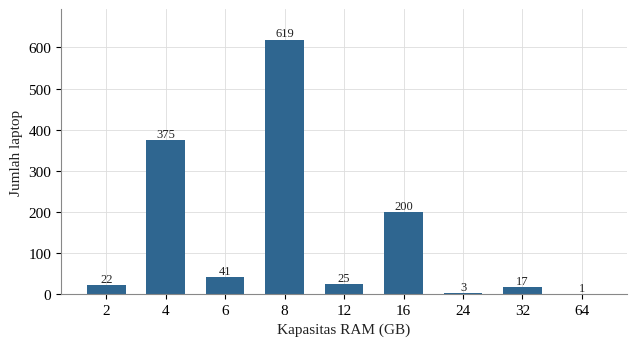

In [ ]:
# Gambar 4.2: Diagram batang kapasitas RAM
rf = R.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6.5, 3.6))

bar = ax.bar(
    [str(i) for i in rf.index],
    rf.values,
    color=BIRU,
    width=0.65
)

# Menampilkan jumlah laptop di atas batang
for b, v in zip(bar, rf.values):
    ax.text(
        b.get_x() + b.get_width() / 2,
        v + 8,
        str(v),
        ha="center",
        fontsize=9
    )

ax.set_xlabel("Kapasitas RAM (GB)")
ax.set_ylabel("Jumlah laptop")
ax.set_ylim(0, rf.max() * 1.12)

plt.tight_layout()
plt.savefig("g_ram.png", dpi=200)
plt.show()

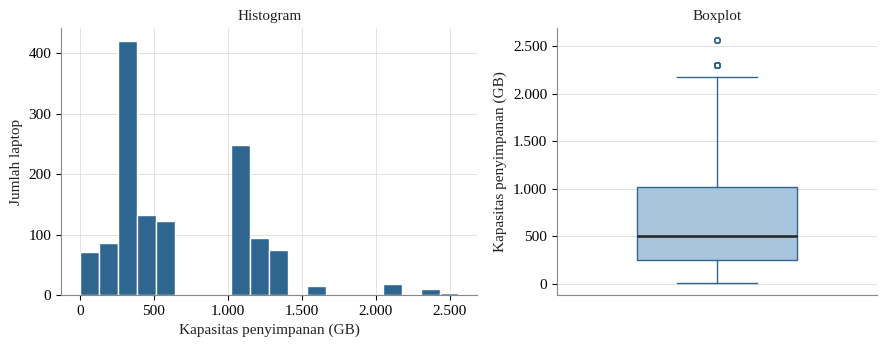

In [ ]:
# Gambar 4.3: Histogram dan boxplot penyimpanan
fig, ax = plt.subplots(
    1, 2,
    figsize=(9, 3.6),
    gridspec_kw={"width_ratios": [1.3, 1]}
)

# Histogram penyimpanan
ax[0].hist(
    S,
    bins=range(0, 2688, 128),
    color=BIRU,
    edgecolor="white",
    linewidth=1
)

ax[0].set_xlabel("Kapasitas penyimpanan (GB)")
ax[0].set_ylabel("Jumlah laptop")
ax[0].xaxis.set_major_formatter(titik)
ax[0].set_title("Histogram", fontsize=11)

# Boxplot penyimpanan
ax[1].boxplot(
    S,
    widths=0.5,
    **kotak
)

ax[1].set_xticks([])
ax[1].yaxis.set_major_formatter(titik)
ax[1].set_ylabel("Kapasitas penyimpanan (GB)")
ax[1].set_title("Boxplot", fontsize=11)

plt.tight_layout()
plt.savefig("g_storage.png", dpi=200)
plt.show()

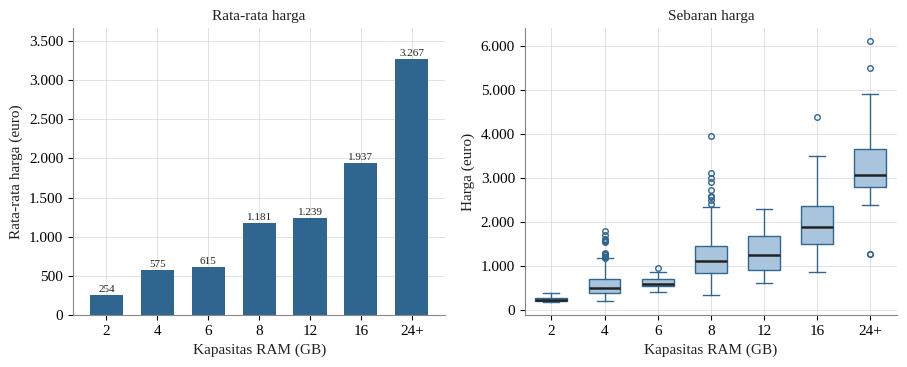

In [ ]:
# Gambar 4.4: Rata-rata dan sebaran harga berdasarkan RAM
fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.8))

# Diagram rata-rata harga
rata = per_ram["mean"].values

bar = ax[0].bar(
    urut,
    rata,
    color=BIRU,
    width=0.65
)

for b, v in zip(bar, rata):
    ax[0].text(
        b.get_x() + b.get_width() / 2,
        v + 40,
        f"{v:,.0f}".replace(",", "."),
        ha="center",
        fontsize=8
    )

ax[0].set_xlabel("Kapasitas RAM (GB)")
ax[0].set_ylabel("Rata-rata harga (euro)")
ax[0].yaxis.set_major_formatter(titik)
ax[0].set_ylim(0, rata.max() * 1.12)
ax[0].set_title("Rata-rata harga", fontsize=11)

# Boxplot harga berdasarkan kelompok RAM
data = [
    df[df["Kelompok_RAM"] == u]["Price_euros"].values
    for u in urut
]

ax[1].boxplot(
    data,
    tick_labels=urut,
    widths=0.6,
    **kotak
)

ax[1].set_xlabel("Kapasitas RAM (GB)")
ax[1].set_ylabel("Harga (euro)")
ax[1].yaxis.set_major_formatter(titik)
ax[1].set_title("Sebaran harga", fontsize=11)

plt.tight_layout()
plt.savefig("g_harga_ram.png", dpi=200)
plt.show()



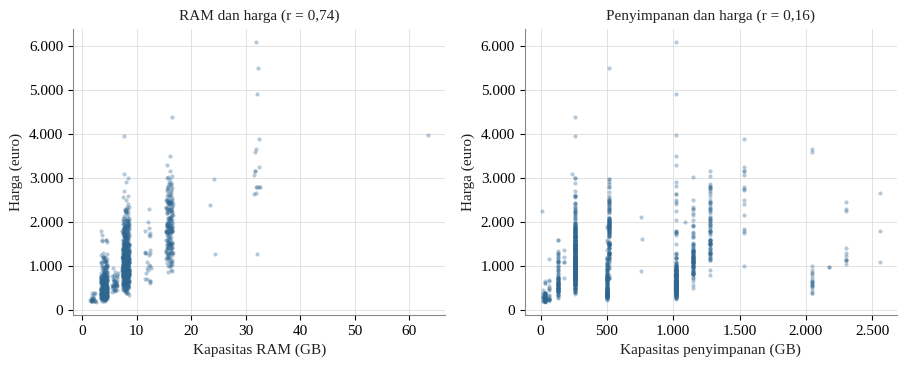

In [ ]:
# Gambar 4.5: Diagram pencar hubungan RAM,
# penyimpanan, dan harga
r = df[
    ["Price_euros", "Ram_GB", "Storage_GB"]
].corr()

acak = np.random.default_rng(1)

fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.8))

# Hubungan RAM dengan harga
ax[0].scatter(
    R + acak.uniform(-0.6, 0.6, len(df)),
    P,
    s=9,
    color=BIRU,
    alpha=0.35,
    linewidths=0
)

ax[0].set_xlabel("Kapasitas RAM (GB)")
ax[0].set_ylabel("Harga (euro)")
ax[0].yaxis.set_major_formatter(titik)

jud = lambda t, v: (
    f"{t} (r = {v:.2f})".replace(".", ",")
)

ax[0].set_title(
    jud("RAM dan harga", r.iloc[0, 1]),
    fontsize=11
)

# Hubungan penyimpanan dengan harga
ax[1].scatter(
    S,
    P,
    s=9,
    color=BIRU,
    alpha=0.35,
    linewidths=0
)

ax[1].set_xlabel("Kapasitas penyimpanan (GB)")
ax[1].set_ylabel("Harga (euro)")
ax[1].yaxis.set_major_formatter(titik)
ax[1].xaxis.set_major_formatter(titik)

ax[1].set_title(
    jud("Penyimpanan dan harga", r.iloc[0, 2]),
    fontsize=11
)

plt.tight_layout()
plt.savefig("g_scatter.png", dpi=200)
plt.show()
